# Retail Analytics & AI-Powered Sales Forecasting
**Role:** Data Scientist, national retail chain · **Data:** `Retail_Sales_Data_Unlox.csv` (Jan 2023 – Dec 2024)

Sections: 1 Data quality · 2 Exploratory analysis · 3 Seasonality & growth drivers · 4 Store segmentation · 5 Time-series forecasting · 6 Conclusions

In [1]:
import warnings, pathlib; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.ensemble import GradientBoostingRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
sns.set_theme(style='whitegrid', palette=['#2f63ff','#16b5a0','#8b5cf6','#f2555a','#f5a524'])
plt.rcParams.update({'figure.dpi':110,'axes.titleweight':'bold','axes.spines.top':False,'axes.spines.right':False})
FIG = pathlib.Path('../report/figures'); FIG.mkdir(parents=True, exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(FIG/f'{name}.png', dpi=160, bbox_inches='tight')
cr = lambda v: v/1e7   # rupees -> crore

## 1. Data quality

In [2]:
df = pd.read_csv('../data/Retail_Sales_Data_Unlox.csv', parse_dates=['Date'])
print('Shape:', df.shape); print('Date range:', df.Date.min().date(), 'to', df.Date.max().date())
print('Missing values:', int(df.isna().sum().sum()), '| Duplicate rows:', int(df.duplicated().sum()))
df.dtypes.to_frame('dtype').T

Shape: (73000, 19)
Date range: 2023-01-01 to 2024-12-31
Missing values: 0 | Duplicate rows: 0


,Date,Store_ID,Store_Location,Product_ID,Product_Category,Product_Subcategory,Brand,Unit_Price,Units_Sold,Total_Sales,Discount_Percentage,Revenue,Customer_Type,Payment_Mode,Promotion_Applied,Stock_On_Hand,Store_Rating,Region,Holiday_Flag
dtype,datetime64[us],str,str,str,str,str,str,float64,int64,float64,int64,float64,str,str,str,int64,float64,str,int64


In [3]:
# Business-rule checks
gross_ok = np.isclose(df.Unit_Price*df.Units_Sold, df.Total_Sales, rtol=1e-3).mean()
rev_ok   = np.isclose(df.Total_Sales*(1-df.Discount_Percentage/100), df.Revenue, rtol=1e-3).mean()
print(f'Total_Sales = Unit_Price x Units_Sold      : {gross_ok:.1%} of rows')
print(f'Revenue = Total_Sales x (1 - discount%)    : {rev_ok:.1%} of rows')
print('Negative / zero values:', int((df[['Unit_Price','Units_Sold','Revenue']]<=0).sum().sum()))
print('Store_ID <-> Store_Location one-to-one:', df.groupby('Store_ID').Store_Location.nunique().max()==1)
print('Days covered:', df.Date.nunique(), '(of 731)')
df.describe().T[['mean','std','min','50%','max']].round(1)

Total_Sales = Unit_Price x Units_Sold      : 100.0% of rows
Revenue = Total_Sales x (1 - discount%)    : 100.0% of rows
Negative / zero values: 0
Store_ID <-> Store_Location one-to-one: True
Days covered: 731 (of 731)


,mean,std,min,50%,max
Date,2023-12-31 11:52:59.835616,NaN,2023-01-01 00:00:00,2023-12-31 00:00:00,2024-12-31 00:00:00
Unit_Price,25110.208554,14393.607981,100.11,25071.8,49999.85
Units_Sold,24.894589,14.134824,1.0,25.0,49.0
Total_Sales,626138.239282,544854.836919,144.7,471357.72,2447350.08
Discount_Percentage,10.010411,7.064131,0.0,10.0,20.0
Revenue,563476.477599,493890.517315,122.995,422356.4515,2447350.08
Stock_On_Hand,274.624712,129.663977,50.0,274.0,499.0
Store_Rating,4.249421,0.434722,3.5,4.2,5.0
Holiday_Flag,0.012288,0.110167,0.0,0.0,1.0


In [4]:
# Outlier screen on revenue (IQR rule): flagged, not removed - large baskets are plausible in retail
q1,q3 = df.Revenue.quantile([.25,.75]); hi = q3+1.5*(q3-q1)
print(f'Revenue rows above IQR fence: {(df.Revenue>hi).mean():.2%} -> kept (right-skew, no data errors)')
df['Month']=df.Date.dt.to_period('M').dt.to_timestamp(); df['Year']=df.Date.dt.year; df['DOW']=df.Date.dt.day_name()
df['Discount_Amt']=df.Total_Sales-df.Revenue

Revenue rows above IQR fence: 1.28% -> kept (right-skew, no data errors)


## 2. Exploratory analysis

In [5]:
k = dict(revenue=df.Revenue.sum(), orders=len(df), units=df.Units_Sold.sum(), aov=df.Revenue.mean(),
         disc=df.Discount_Percentage.mean(), given=df.Discount_Amt.sum(), rating=df.Store_Rating.mean())
y = df.groupby('Year').Revenue.sum()
print(f"Revenue ₹{cr(k['revenue']):,.0f} Cr | Orders {k['orders']:,} | Units {k['units']:,} | Avg order ₹{k['aov']/1e5:.1f} L")
print(f"Discounts given ₹{cr(k['given']):,.0f} Cr (avg {k['disc']:.1f}%) | Avg rating {k['rating']:.2f}")
print(f"2023 ₹{cr(y[2023]):,.0f} Cr -> 2024 ₹{cr(y[2024]):,.0f} Cr  ({(y[2024]/y[2023]-1):+.2%})")

Revenue ₹4,113 Cr | Orders 73,000 | Units 1,817,305 | Avg order ₹5.6 L
Discounts given ₹457 Cr (avg 10.0%) | Avg rating 4.25
2023 ₹2,064 Cr -> 2024 ₹2,049 Cr  (-0.72%)


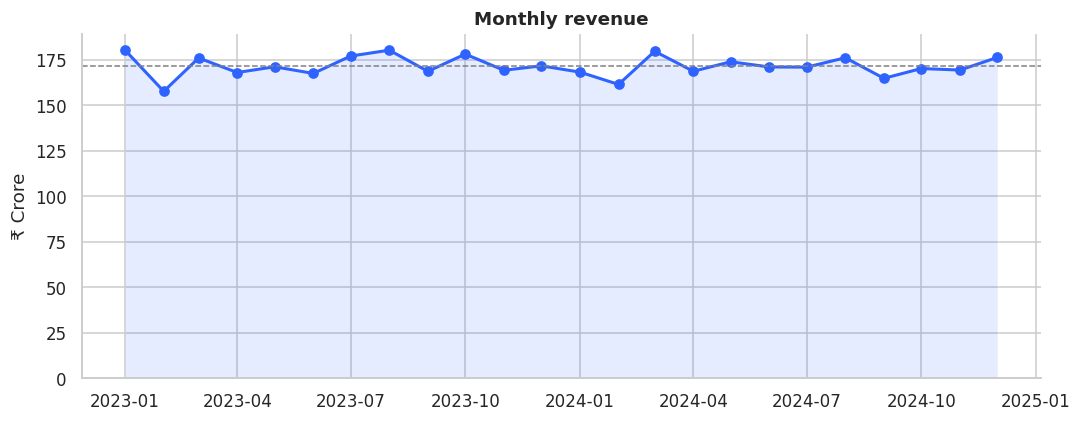

In [6]:
m = df.groupby('Month').Revenue.sum().map(cr)
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(m.index, m.values, marker='o', lw=2); ax.fill_between(m.index, m.values, alpha=.12)
ax.axhline(m.mean(), ls='--', c='grey', lw=1); ax.set_ylabel('₹ Crore'); ax.set_title('Monthly revenue'); ax.set_ylim(0)
save('01_monthly_revenue'); plt.show()

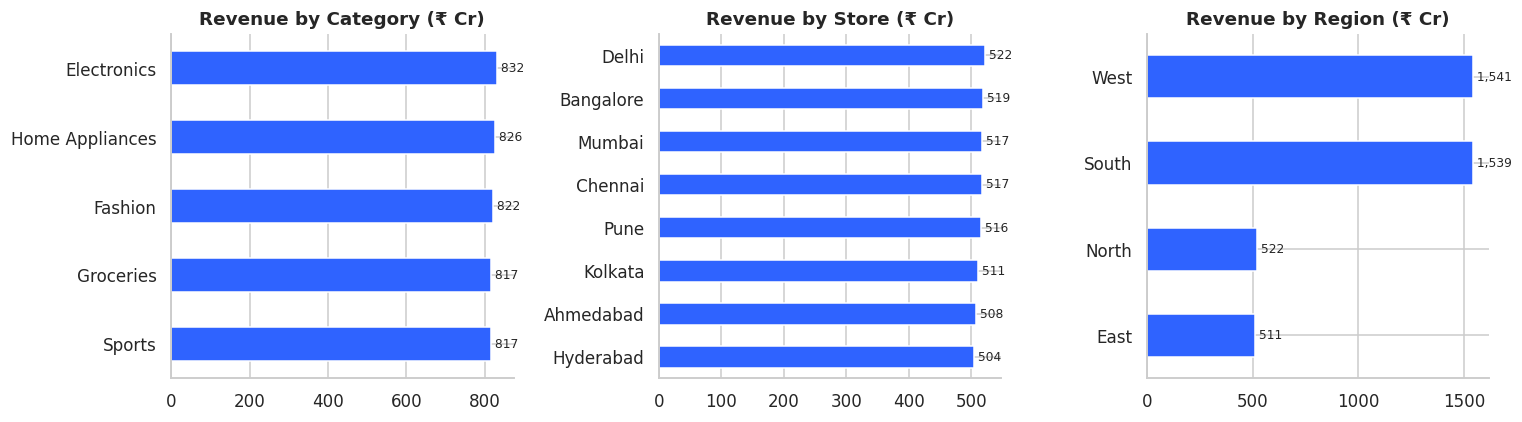

,revenue_cr,orders,rating
Store_Location,,,
Delhi,522.31,9173,4.25
Bangalore,518.63,9174,4.25
Mumbai,516.97,9039,4.25
Chennai,516.59,9186,4.25
Pune,516.19,9254,4.25
Kolkata,510.78,9136,4.25
Ahmedabad,507.83,9024,4.25
Hyderabad,504.08,9014,4.25


In [7]:
fig, axs = plt.subplots(1,3, figsize=(14,4))
for ax,(col,t) in zip(axs,[('Product_Category','Category'),('Store_Location','Store'),('Region','Region')]):
    s = df.groupby(col).Revenue.sum().map(cr).sort_values()
    s.plot.barh(ax=ax, color='#2f63ff'); ax.set_title(f'Revenue by {t} (₹ Cr)'); ax.set_ylabel('')
    for i,v in enumerate(s): ax.text(v, i, f' {v:,.0f}', va='center', fontsize=8)
save('02_category_store_region'); plt.show()
df.groupby('Store_Location').agg(revenue_cr=('Revenue',lambda x: cr(x.sum())), orders=('Revenue','size'), rating=('Store_Rating','mean')).sort_values('revenue_cr',ascending=False).round(2)

In [8]:
sub = df.groupby(['Product_Category','Product_Subcategory']).Revenue.sum().map(cr).round(0).reset_index()
br  = df.groupby('Brand').Revenue.sum().map(cr).sort_values(ascending=False).head(8).round(0)
print(br.to_string()); sub.sort_values('Revenue',ascending=False).head(8)

Brand
Levis       214.0
Amul        211.0
OnePlus     209.0
Samsung     209.0
LG          208.0
Sony        208.0
Philips     208.0
Prestige    206.0


,Product_Category,Product_Subcategory,Revenue
1,Electronics,Laptops,281.0
3,Fashion,Footwear,279.0
9,Home Appliances,Cleaning,278.0
14,Sports,Outdoor,277.0
0,Electronics,Accessories,277.0
8,Groceries,Snacks,276.0
11,Home Appliances,Lighting,276.0
13,Sports,Gym Equipment,274.0


## 3. Seasonality and growth drivers

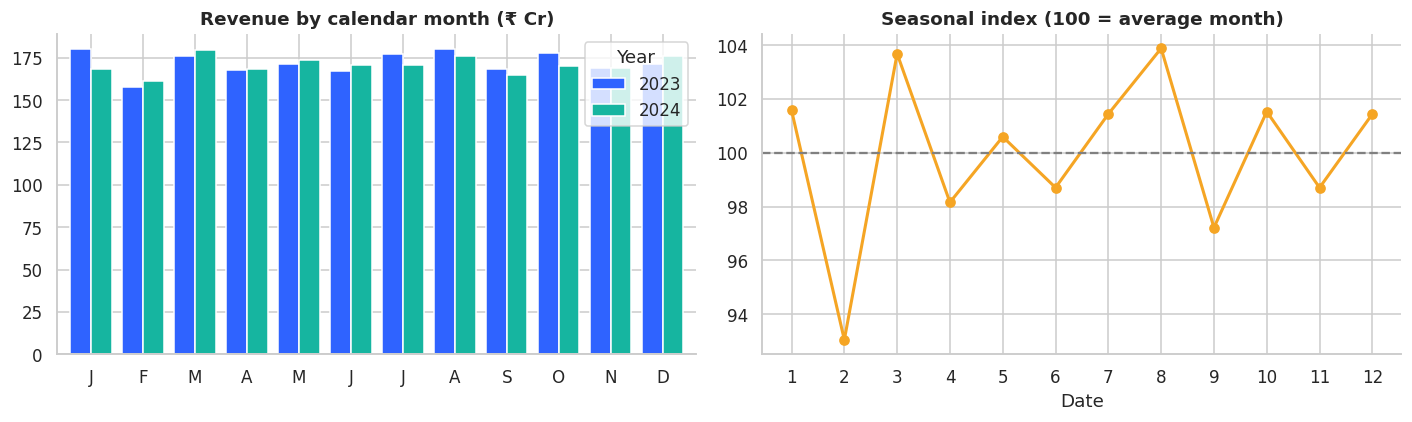

Peak month: 8 103.9 | Weakest: 2 93.0


In [9]:
mon = df.groupby(['Year', df.Date.dt.month]).Revenue.sum().unstack(0).map(cr)
idx = (mon/mon.mean()*100).mean(axis=1)
fig, ax = plt.subplots(1,2, figsize=(13,4))
mon.plot.bar(ax=ax[0], width=.8); ax[0].set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'], rotation=0); ax[0].set_title('Revenue by calendar month (₹ Cr)'); ax[0].set_xlabel('')
idx.plot(ax=ax[1], marker='o', color='#f5a524', lw=2); ax[1].axhline(100, c='grey', ls='--'); ax[1].set_title('Seasonal index (100 = average month)'); ax[1].set_xticks(range(1,13))
save('03_seasonality'); plt.show()
print('Peak month:', idx.idxmax(), round(idx.max(),1), '| Weakest:', idx.idxmin(), round(idx.min(),1))

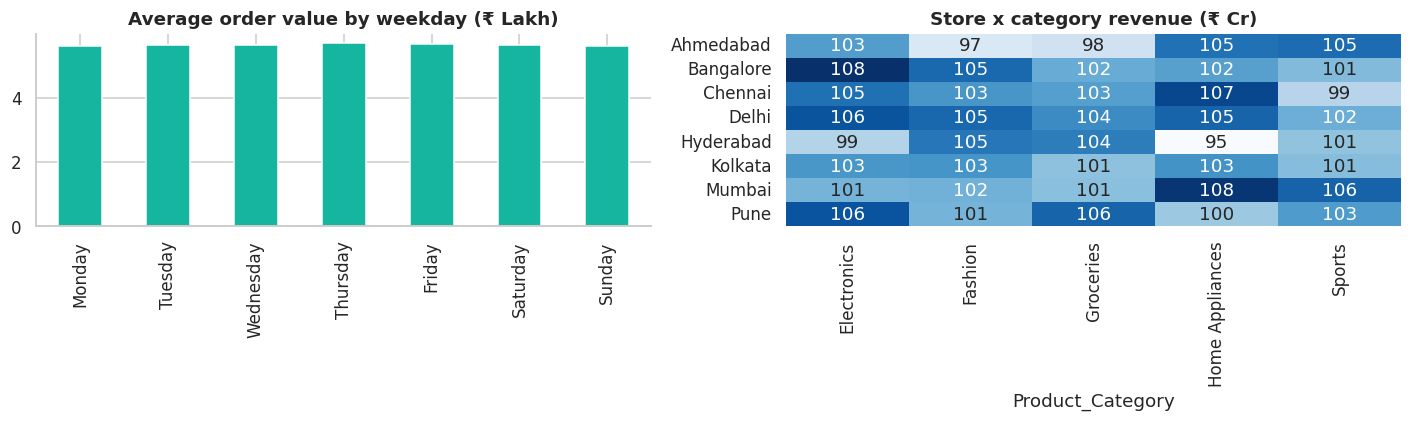

In [10]:
d = df.groupby('DOW').Revenue.mean().reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])/1e5
fig, ax = plt.subplots(1,2, figsize=(13,4))
d.plot.bar(ax=ax[0], color='#16b5a0'); ax[0].set_title('Average order value by weekday (₹ Lakh)'); ax[0].set_xlabel('')
pv = df.pivot_table(index='Store_Location', columns='Product_Category', values='Revenue', aggfunc='sum').map(cr)
sns.heatmap(pv, annot=True, fmt='.0f', cmap='Blues', ax=ax[1], cbar=False); ax[1].set_title('Store x category revenue (₹ Cr)'); ax[1].set_ylabel('')
save('04_weekday_heatmap'); plt.show()

In [11]:
# Which levers move revenue? Compare average order value & units across levers
rows=[]
for col in ['Promotion_Applied','Holiday_Flag','Customer_Type','Payment_Mode']:
    g = df.groupby(col).agg(avg_order_L=('Revenue',lambda x:x.mean()/1e5), avg_units=('Units_Sold','mean'), orders=('Revenue','size')).round(2)
    g.insert(0,'lever',col); rows.append(g.reset_index().rename(columns={col:'value'}))
lev = pd.concat(rows); print(lev.to_string(index=False))
disc = df.groupby('Discount_Percentage').agg(units=('Units_Sold','mean'), rev=('Revenue','mean'))
print(f"\nUnits per order across discount levels: {disc.units.min():.1f} to {disc.units.max():.1f} (spread {(disc.units.max()-disc.units.min())/disc.units.mean():.1%})")

      value             lever  avg_order_L  avg_units  orders
         No Promotion_Applied         5.64      24.90   51151
        Yes Promotion_Applied         5.62      24.88   21849
          0      Holiday_Flag         5.64      24.91   72103
          1      Holiday_Flag         5.49      23.85     897
        New     Customer_Type         5.65      24.82   29218
  Returning     Customer_Type         5.63      24.94   43782
       Cash      Payment_Mode         5.66      24.90   18147
Credit Card      Payment_Mode         5.67      24.91   18354
 Debit Card      Payment_Mode         5.59      24.85   18338
        UPI      Payment_Mode         5.62      24.92   18161

Units per order across discount levels: 24.8 to 25.0 (spread 0.9%)


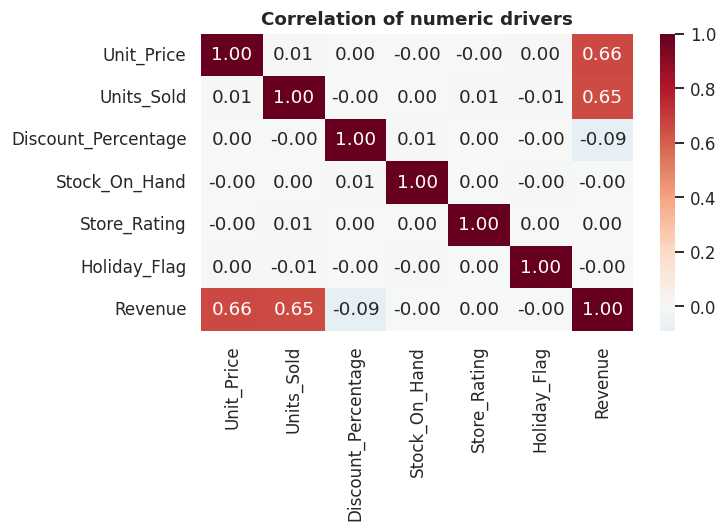

Revenue is driven mechanically by price x units; discount, promo, rating and stock show ~no relationship.


In [12]:
num = df[['Unit_Price','Units_Sold','Discount_Percentage','Stock_On_Hand','Store_Rating','Holiday_Flag','Revenue']]
fig, ax = plt.subplots(figsize=(7,5)); sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax); ax.set_title('Correlation of numeric drivers')
save('05_correlation'); plt.show()
print('Revenue is driven mechanically by price x units; discount, promo, rating and stock show ~no relationship.')

## 4. Store segmentation (K-Means)

In [13]:
s = df.groupby(['Store_ID','Store_Location','Region']).agg(revenue=('Revenue','sum'), aov=('Revenue','mean'), rating=('Store_Rating','mean'),
        discount=('Discount_Percentage','mean'), returning=('Customer_Type',lambda x:(x=='Returning').mean()*100)).reset_index()
yr = df.pivot_table(index='Store_ID', columns='Year', values='Revenue', aggfunc='sum'); s['growth']=(s.Store_ID.map(yr[2024]/yr[2023]-1)*100).values
F = ['revenue','aov','rating','discount','returning','growth']; X = StandardScaler().fit_transform(s[F])
for k in range(2,6): print(k, 'clusters  silhouette =', round(silhouette_score(X, KMeans(k,n_init=20,random_state=42).fit_predict(X)),3))

2 clusters  silhouette = 0.2
3 clusters  silhouette = 0.205
4 clusters  silhouette = 0.211
5 clusters  silhouette = 0.175


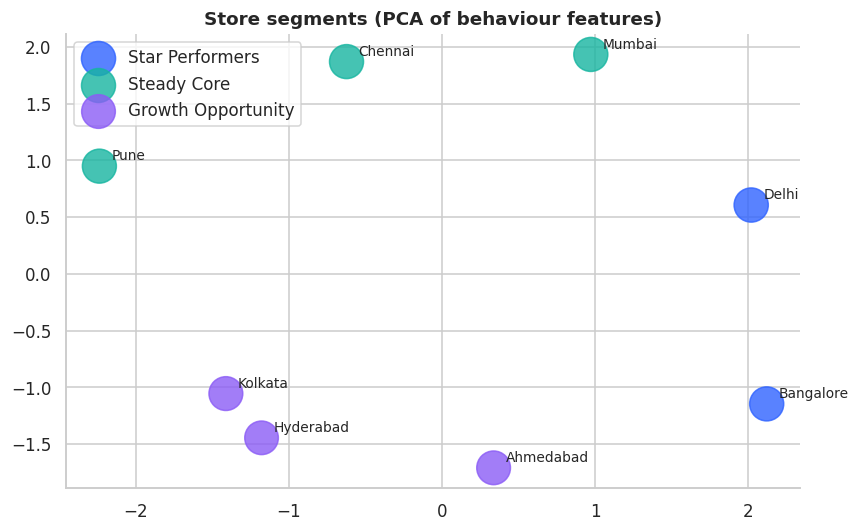

,Store_Location,Region,segment,revenue_cr,aov,rating,growth,returning
2,Delhi,North,Star Performers,522.31,569395.43,4.25,-2.34,59.34
1,Bangalore,South,Star Performers,518.63,565323.37,4.25,3.66,59.12
0,Mumbai,West,Steady Core,516.97,571930.00,4.25,-2.12,60.18
3,Chennai,South,Steady Core,516.59,562370.72,4.25,-2.11,60.82
4,Pune,West,Steady Core,516.19,557801.89,4.25,-1.77,60.31
6,Kolkata,East,Growth Opportunity,510.78,559088.47,4.25,0.88,60.61
7,Ahmedabad,West,Growth Opportunity,507.83,562757.31,4.25,-0.25,59.36
5,Hyderabad,South,Growth Opportunity,504.08,559216.36,4.25,-1.54,60.05


In [14]:
km = KMeans(3, n_init=20, random_state=42).fit(X); s['cluster']=km.labels_
order = s.groupby('cluster').revenue.mean().sort_values(ascending=False).index
s['segment']=s.cluster.map(dict(zip(order,['Star Performers','Steady Core','Growth Opportunity'])))
p = PCA(2, random_state=1).fit_transform(X)
fig, ax = plt.subplots(figsize=(8,5))
for g,c in zip(['Star Performers','Steady Core','Growth Opportunity'],['#2f63ff','#16b5a0','#8b5cf6']):
    t = s.segment==g; ax.scatter(p[t,0],p[t,1], s=s.revenue[t]/s.revenue.max()*500, c=c, alpha=.8, label=g)
for i,r in s.iterrows(): ax.annotate(r.Store_Location,(p[i,0],p[i,1]), xytext=(8,4), textcoords='offset points', fontsize=9)
ax.legend(); ax.set_title('Store segments (PCA of behaviour features)'); save('06_segments'); plt.show()
s.assign(revenue_cr=s.revenue.map(cr)).sort_values('revenue',ascending=False)[['Store_Location','Region','segment','revenue_cr','aov','rating','growth','returning']].round(2)

## 5. Time-series forecasting
Monthly revenue has **24 points**. Candidate models are scored on the **last 4 months held out**:
ARIMA, SARIMA, damped-trend ETS, seasonally-adjusted ETS, trend+seasonal regression, gradient boosting, and a 3-month moving-average benchmark.
Full Holt-Winters needs ≥2 seasonal cycles in the *training* set (we only have 20 months), so it is replaced by a seasonally-adjusted ETS.

In [15]:
y = df.groupby('Month').Revenue.sum(); v = y.values.astype(float); TEST, H = 4, 6
def mape(a,f): return float(np.mean(np.abs((a-f)/a))*100)
def feats(t): t=np.asarray(t); m=t%12; return np.column_stack([t,np.sin(2*np.pi*m/12),np.cos(2*np.pi*m/12)])
def ets(tr,h): return np.asarray(ExponentialSmoothing(tr,trend='add',damped_trend=True,initialization_method='estimated').fit().forecast(h))
def sets(tr,h):
    n=len(tr); i=np.arange(n)%12; si=np.array([tr[i==k].mean() for k in range(12)]); si/=si.mean()
    return ets(tr/si[i],h)*si[np.arange(n,n+h)%12]
def lin(tr,h):
    t=np.arange(len(tr)); A=np.column_stack([np.ones(len(t)),feats(t)]); b=np.linalg.lstsq(A,tr,rcond=None)[0]; tf=np.arange(len(tr),len(tr)+h)
    return np.column_stack([np.ones(h),feats(tf)])@b
def gbm(tr,h):
    t=np.arange(len(tr)); c=np.polyfit(t,tr,1); m=GradientBoostingRegressor(n_estimators=150,max_depth=2,learning_rate=.05,random_state=0).fit(feats(t),tr-np.polyval(c,t))
    tf=np.arange(len(tr),len(tr)+h); return np.polyval(c,tf)+m.predict(feats(tf))
def arima(tr,h): return np.asarray(ARIMA(tr,order=(1,1,1)).fit().forecast(h))
def sarima(tr,h): return np.asarray(SARIMAX(tr,order=(1,0,0),seasonal_order=(0,1,0,12)).fit(disp=False).forecast(h))
def ma(tr,h): return np.repeat(tr[-3:].mean(),h)
MODELS={'ARIMA(1,1,1)':arima,'SARIMA(1,0,0)(0,1,0,12)':sarima,'Damped-trend ETS':ets,'Seasonal-adjusted ETS':sets,'Trend+seasonal regression':lin,'Gradient boosting':gbm,'Moving average (benchmark)':ma}
tr,te = v[:-TEST], v[-TEST:]; res=[]; preds={}
for n,f in MODELS.items():
    try: p=f(tr,TEST); preds[n]=p; res.append((n, mape(te,p), np.sqrt(np.mean((te-p)**2))/1e7, np.mean(np.abs(te-p))/1e7))
    except Exception as e: res.append((n, np.nan, np.nan, np.nan)); print('failed', n, e)
board = pd.DataFrame(res, columns=['Model','MAPE %','RMSE (₹ Cr)','MAE (₹ Cr)']).sort_values('MAPE %').round(2).reset_index(drop=True); board

,Model,MAPE %,RMSE (₹ Cr),MAE (₹ Cr)
0,Seasonal-adjusted ETS,2.44,4.80,4.17
1,Damped-trend ETS,2.44,4.60,4.12
2,"SARIMA(1,0,0)(0,1,0,12)",2.46,5.01,4.19
3,Moving average (benchmark),2.57,4.80,4.33
4,Trend+seasonal regression,3.10,5.87,5.24
5,Gradient boosting,3.11,5.65,5.26
6,"ARIMA(1,1,1)",3.48,6.87,5.82


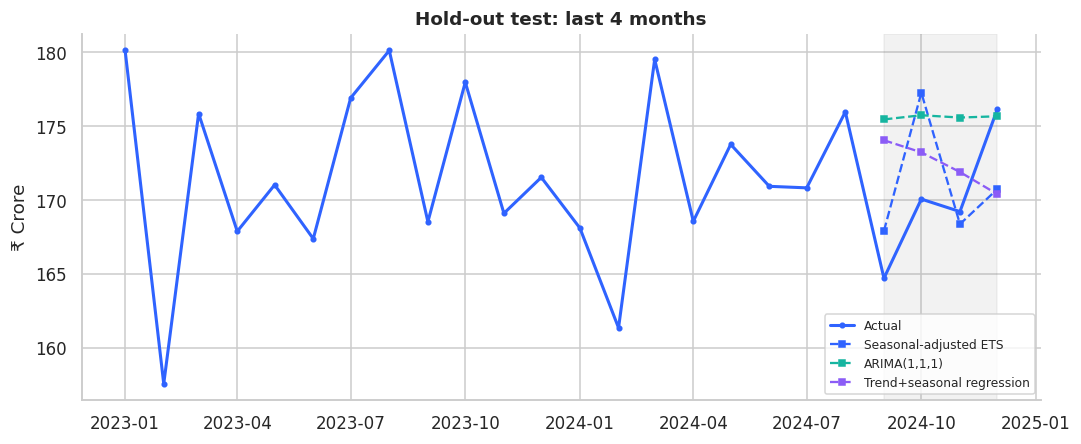

In [16]:
fig, ax = plt.subplots(figsize=(10,4.2)); ax.plot(y.index, v/1e7, c='#2f63ff', lw=2, label='Actual', marker='o', ms=3)
for n in ['Seasonal-adjusted ETS','ARIMA(1,1,1)','Trend+seasonal regression']:
    if n in preds: ax.plot(y.index[-TEST:], preds[n]/1e7, ls='--', marker='s', ms=4, label=n)
ax.axvspan(y.index[-TEST], y.index[-1], color='grey', alpha=.1); ax.legend(fontsize=8); ax.set_ylabel('₹ Crore'); ax.set_title('Hold-out test: last 4 months')
save('07_holdout'); plt.show()

Selected model: Seasonal-adjusted ETS | hold-out MAPE 2.44 %


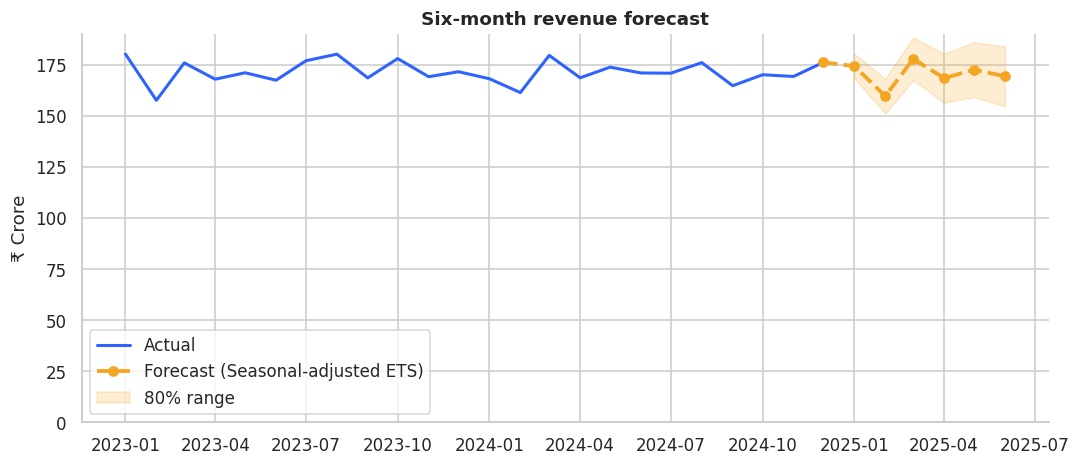

  Month  Forecast (₹ Cr)   Low  High
2025-01            174.3 168.3 180.3
2025-02            159.6 151.1 168.1
2025-03            177.9 167.5 188.3
2025-04            168.4 156.4 180.4
2025-05            172.6 159.1 186.0
2025-06            169.3 154.6 184.0

Total next 6 months: ₹1,022 Cr vs last 6 months ₹1,027 Cr (-0.5%)


In [17]:
cand = board[~board.Model.str.contains('benchmark')]; best = cand.iloc[0].Model; print('Selected model:', best, '| hold-out MAPE', cand.iloc[0]['MAPE %'], '%')
fc = MODELS[best](v, H); fidx = pd.date_range(y.index[-1]+pd.offsets.MonthBegin(1), periods=H, freq='MS')
sd = max(np.std(te-preds[best]), v.std()*.05); band = 1.28*sd*np.sqrt(np.arange(1,H+1))
fig, ax = plt.subplots(figsize=(10,4.4)); ax.plot(y.index, v/1e7, c='#2f63ff', lw=2, label='Actual')
ax.plot([y.index[-1],*fidx], [v[-1]/1e7,*(fc/1e7)], c='#f5a524', lw=2.5, ls='--', marker='o', label=f'Forecast ({best})')
ax.fill_between(fidx, (fc-band)/1e7, (fc+band)/1e7, color='#f5a524', alpha=.2, label='80% range'); ax.set_ylim(0); ax.legend(); ax.set_ylabel('₹ Crore'); ax.set_title('Six-month revenue forecast')
save('08_forecast'); plt.show()
out = pd.DataFrame({'Month':fidx.strftime('%Y-%m'),'Forecast (₹ Cr)':fc/1e7,'Low':(fc-band)/1e7,'High':(fc+band)/1e7}).round(1); print(out.to_string(index=False))
print(f'\nTotal next 6 months: ₹{fc.sum()/1e7:,.0f} Cr vs last 6 months ₹{v[-6:].sum()/1e7:,.0f} Cr ({fc.sum()/v[-6:].sum()-1:+.1%})')

In [18]:
# Forecast by category and by store (best of damped ETS / seasonal ETS / regression by hold-out MAPE)
def best_fc(s):
    s=s.values.astype(float); tr,te=s[:-TEST],s[-TEST:]; sc={}
    for n in ['Damped-trend ETS','Seasonal-adjusted ETS','Trend+seasonal regression']:
        try: sc[n]=mape(te,MODELS[n](tr,TEST))
        except Exception: pass
    b=min(sc,key=sc.get); return b, sc[b], MODELS[b](s,H).sum()/1e7, s[-H:].sum()/1e7
full = y.index; rows=[]
for col in ['Product_Category','Store_Location']:
    for name,g in df.groupby(col):
        b,m_,f_,l_ = best_fc(g.groupby('Month').Revenue.sum().reindex(full,fill_value=0)); rows.append((col.split('_')[0],name,b,round(m_,1),round(f_,0),round(l_,0),f'{f_/l_-1:+.1%}'))
pd.DataFrame(rows, columns=['Level','Name','Model','MAPE %','Next 6m (₹ Cr)','Last 6m (₹ Cr)','Change'])

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


,Level,Name,Model,MAPE %,Next 6m (₹ Cr),Last 6m (₹ Cr),Change
0,Product,Electronics,Damped-trend ETS,7.4,206.0,202.0,+2.0%
1,Product,Fashion,Damped-trend ETS,7.4,206.0,203.0,+1.6%
2,Product,Groceries,Damped-trend ETS,1.6,206.0,207.0,-0.5%
3,Product,Home Appliances,Seasonal-adjusted ETS,5.6,201.0,208.0,-3.5%
4,Product,Sports,Damped-trend ETS,2.2,206.0,207.0,-0.9%
5,Store,Ahmedabad,Seasonal-adjusted ETS,1.7,123.0,124.0,-0.2%
6,Store,Bangalore,Seasonal-adjusted ETS,1.7,132.0,129.0,+2.1%
7,Store,Chennai,Damped-trend ETS,5.5,130.0,127.0,+2.6%
8,Store,Delhi,Seasonal-adjusted ETS,7.4,130.0,127.0,+2.1%
9,Store,Hyderabad,Trend+seasonal regression,9.0,123.0,120.0,+2.4%


## 6. Conclusions and recommendations
1. **Revenue is flat** (≈ −0.7% YoY); the business is stable rather than growing. Growth must come from new levers, not from existing promotions.
2. **Categories are balanced (~20% each)** and **Delhi, Bangalore** lead stores; **Hyderabad** trails but only by a few percent, so no store is a clear laggard.
3. **Seasonality is mild** (index ≈ 93–104): August peak, February trough. Use for stock and staffing, not for large budget shifts.
4. **Discounts and promotions show no measurable volume lift**, yet cost ≈ ₹457 Cr in discounts. Recommend a controlled A/B test before continuing blanket discounts.
5. **Forecast:** Next six months ≈ ₹1,022 Cr (about ₹170 Cr a month, -0.5% vs the previous six months); the chosen model has ~2.4% hold-out error and ties with damped ETS and SARIMA, so the choice among them is not decisive. Treat per-category forecasts (MAPE 2–7%) with more caution.
6. **Limitations:** only 24 months of history, no external data (price, competition, events); the data behaves like a simulation, so weak relationships are expected. Re-train monthly as new data arrives.